# <font color='gold'> Segmentation des publications Facebook

**Jeu de données :** Facebook Live Sellers in Thailand — UCI Machine Learning Repository

**Lien :** [https://archive.ics.uci.edu/dataset/488/facebook+live+sellers+in+thailand](https://archive.ics.uci.edu/dataset/488/facebook+live+sellers+in+thailand)

### <font color='gold'> Import les librairies requises

In [1]:
# Importer  packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
 # Supprimer les warnings
 import warnings
 warnings.filterwarnings('ignore')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


###<font color='gold'> Importer et lire les données

In [4]:
# Importer data
df = pd.read_csv("/content/drive/MyDrive/Machine Learning/EXAMEN ML/Facebook_Live_Sellers/Live_20210128.csv")

#### Description des variables du jeu de données "Facebook Live Sellers in Thailand" (UCI)

Ce jeu de données contient les publications Facebook de 10 vendeurs thaïlandais (mode et cosmétiques) et les réactions qu'elles ont suscitées. L'objectif est d'effectuer une segmentation (clustering) des publications pour identifier des groupes homogènes selon l'engagement.

| Variable | Type | Description |
|----------|------|-------------|
| `status_id` | Numérique | Identifiant de la publication. |
| `status_type` | Catégorielle | Type de publication : video, photo, status, link. |
| `status_published` | Texte | Date et heure de publication. |
| `num_reactions` | Numérique | Nombre total de réactions. |
| `num_comments` | Numérique | Nombre de commentaires. |
| `num_shares` | Numérique | Nombre de partages. |
| `num_likes` | Numérique | Nombre de « J'aime ». |
| `num_loves` | Numérique | Nombre de « J'adore ». |
| `num_wows` | Numérique | Nombre de « Wouah ». |
| `num_hahas` | Numérique | Nombre de « Haha ». |
| `num_sads` | Numérique | Nombre de « Triste ». |
| `num_angrys` | Numérique | Nombre de « Grrr ». |
| `Column1` … `Column4` | Numérique | Colonnes vides (à supprimer). |

In [5]:
# Afficher les données
df.head()

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


In [6]:
# Dimension des données
df.shape

(7050, 16)

In [7]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10), object(2)
memory

In [8]:
# décrire les données
df.describe()

,status_id,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,0.0,0.0,0.0,0.0
mean,3525.500000,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191,NaN,NaN,NaN,NaN
std,2035.304031,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812,NaN,NaN,NaN,NaN
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,1763.250000,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,3525.500000,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,5287.750000,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
max,7050.000000,4710.000000,20990.000000,3424.000000,4710.000000,657.000000,278.000000,157.000000,51.000000,31.000000,NaN,NaN,NaN,NaN


### <font color='gold'> Nettoyage des données

In [9]:
# Valeurs manquantes par variable
df.isna().sum()

,0
status_id,0
status_type,0
status_published,0
num_reactions,0
num_comments,0
num_shares,0
num_likes,0
num_loves,0
num_wows,0
num_hahas,0


In [10]:
# Supprimer les colonnes vide
df = df.drop(['Column1', 'Column2', 'Column3', 'Column4'], axis=1)

In [11]:
# Nombre de posts en double
df.drop('status_id', axis=1).duplicated().sum()

np.int64(54)

In [12]:
# Supprimer les doublons
df = df.drop_duplicates(subset=df.columns.drop('status_id'))
df.shape

(6996, 12)

In [13]:
# Supprimer l'identifiant et la date de publication
df = df.drop(['status_id', 'status_published'], axis=1)

In [14]:
# Enregistrer les valeurs uniques de la variable catégorielle dans un objet joblib
import joblib as jb
uniques = np.unique(df['status_type']).tolist()
jb.dump(uniques,"/content/drive/MyDrive/Machine Learning/EXAMEN ML/Facebook_Live_Sellers/uniques.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML/Facebook_Live_Sellers/uniques.joblib']

In [15]:
# Encoder la variable catégorielle status_type
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df['status_type'] = encoder.fit_transform(df['status_type'])
df.head()

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,3,529,512,262,432,92,3,1,1,0
1,1,150,0,0,150,0,0,0,0,0
2,3,227,236,57,204,21,1,1,0,0
3,1,111,0,0,111,0,0,0,0,0
4,1,213,0,0,204,9,0,0,0,0


In [16]:
# Dimension des données nettoyées
df.shape

(6996, 10)

### <font color='gold'> Preparation des données

In [17]:
# renommer les index
df.index = ['Post' + str(i+1) for i in range(len(df))]
df.head()

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
Post1,3,529,512,262,432,92,3,1,1,0
Post2,1,150,0,0,150,0,0,0,0,0
Post3,3,227,236,57,204,21,1,1,0,0
Post4,1,111,0,0,111,0,0,0,0,0
Post5,1,213,0,0,204,9,0,0,0,0


In [18]:
import joblib as jb
jb.dump(df.columns.tolist(),"/content/drive/MyDrive/Machine Learning/EXAMEN ML/Facebook_Live_Sellers/colonnes.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML/Facebook_Live_Sellers/colonnes.joblib']

In [19]:
# Données en format matriciel
x = df.values
x[:5]

array([[  3, 529, 512, 262, 432,  92,   3,   1,   1,   0],
       [  1, 150,   0,   0, 150,   0,   0,   0,   0,   0],
       [  3, 227, 236,  57, 204,  21,   1,   1,   0,   0],
       [  1, 111,   0,   0, 111,   0,   0,   0,   0,   0],
       [  1, 213,   0,   0, 204,   9,   0,   0,   0,   0]])

In [20]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)
x[:5]

array([[0.00334214, 0.58933064, 0.57039184, 0.2918802 , 0.48126812,
        0.10249228, 0.00334214, 0.00111405, 0.00111405, 0.        ],
       [0.00471399, 0.70709892, 0.        , 0.        , 0.70709892,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.00768116, 0.58120741, 0.60425087, 0.14594195, 0.52231855,
        0.05376809, 0.00256039, 0.00256039, 0.        , 0.        ],
       [0.0063702 , 0.70709243, 0.        , 0.        , 0.70709243,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.00338901, 0.72185973, 0.        , 0.        , 0.69135861,
        0.03050112, 0.        , 0.        , 0.        , 0.        ]])

In [21]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca_model= PCA(n_components = 2)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice features_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])

In [22]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(93.4)

### <font color='gold'> Kmeans

In [23]:
# Importer KMeans
from sklearn.cluster import KMeans

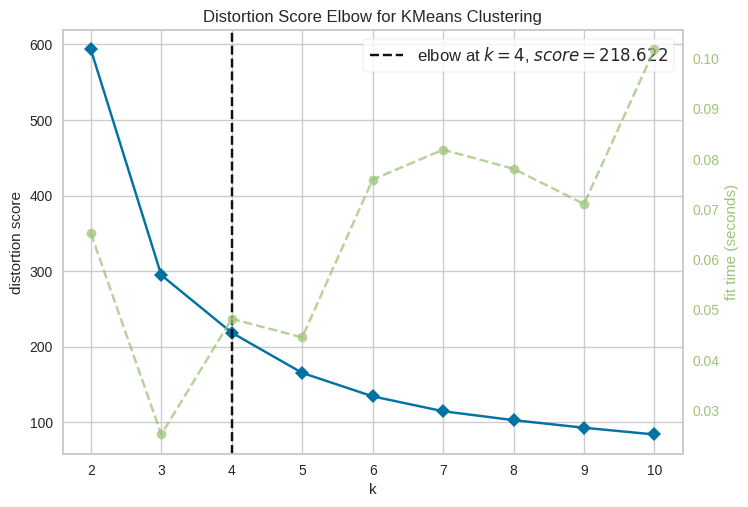

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [24]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

In [25]:
# instantier le modèle
kmeans_model = KMeans(n_clusters=4,init="random",max_iter=500)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=4)

#### <font color='teal'> Prédiction

In [26]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition[:100]

array([1, 3, 1, 3, 3, 3, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 0, 1, 1, 3, 3, 3,
       3, 3, 3, 3, 1, 1, 3, 1, 3, 3, 3, 3, 3, 3, 1, 3, 3, 1, 1, 3, 1, 1,
       3, 1, 3, 1, 1, 1, 3, 1, 3, 1, 1, 1, 1, 1, 1, 1, 3, 1, 3, 1, 3, 3,
       1, 1, 1, 1, 3, 1, 1, 1, 1, 3, 1, 3, 1, 3, 1, 1, 1, 1, 1, 3, 3, 3,
       3, 1, 1, 3, 3, 3, 3, 3, 3, 1, 1, 1], dtype=int32)

In [27]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
print(val)

3    5142
0     908
1     561
2     385
Name: count, dtype: int64


In [28]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [29]:
# visualion le diagramme des nombres d'observations
bar_plot(val)

In [30]:
# Function de visualisuation des classes
def scatter_plot(New_df,Pred):
  fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

In [31]:
# Visualiser les classes
scatter_plot(New_df,kmeans_partition)

##### <font color='teal'> Indice de silhouette de la partition du Kmeans

In [32]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_kmeans = silhouette_score(x,kmeans_partition)
print(f"La silhouette: {sil_kmeans} ")

La silhouette: 0.6855893930759045 


### <font color='gold'> CAH

In [33]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

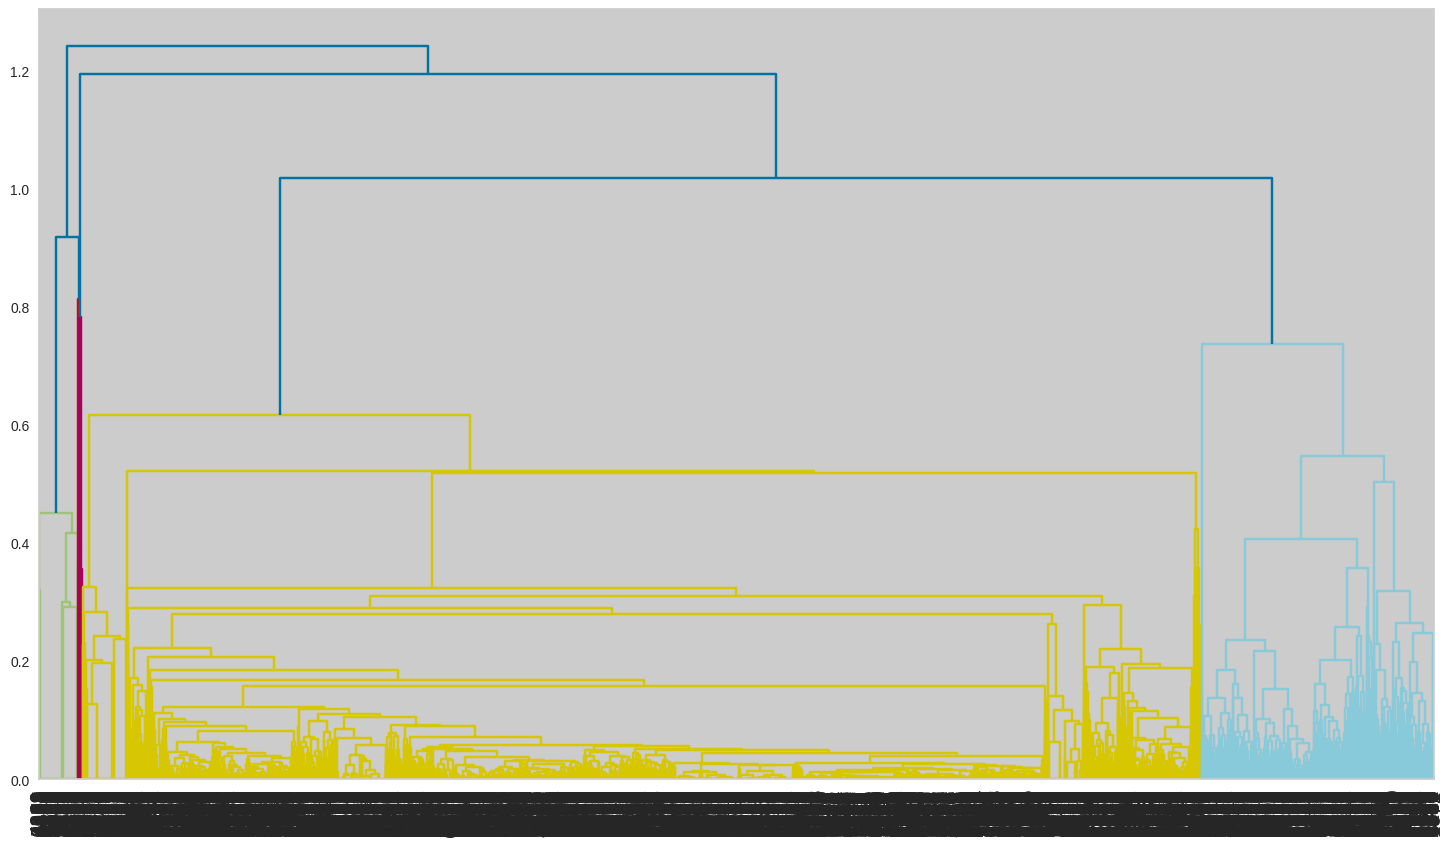

In [34]:
# Visualiser le dendrograme (
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 10))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [35]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters=4,linkage="average")
# Entrainer le modèle
cah_model.fit(x)

AgglomerativeClustering(linkage='average', n_clusters=4)

In [36]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[:100]

array([1, 3, 1, 3, 3, 3, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 1, 1, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 1, 3, 1, 3, 3, 3, 3, 3, 3, 1, 3, 3, 1, 3, 3, 3, 1,
       3, 1, 3, 3, 1, 1, 3, 3, 3, 1, 3, 1, 1, 3, 3, 1, 3, 1, 3, 1, 3, 3,
       1, 1, 3, 1, 3, 1, 1, 3, 1, 3, 1, 3, 1, 3, 3, 3, 1, 1, 1, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 1, 1, 1])

In [37]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

,count
3,5613
1,1164
0,200
2,19


In [38]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [39]:
# Visualiser les classes
scatter_plot(New_df,cah_partition)

In [40]:
# Silhouette score
sil_cah = silhouette_score(x,cah_partition)
print(f"La silhouette: {sil_cah} ")

La silhouette: 0.7594218741844261 


In [41]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [42]:
# les indidivus
cluster_names = []
for i in range(4):
 cluster_names.append(list(df.index[cah_partition== i]))

In [43]:
# Les individus de la classe 0
print(cluster_names[0])

['Post1322', 'Post1857', 'Post2047', 'Post3118', 'Post3677', 'Post3683', 'Post3685', 'Post3708', 'Post3728', 'Post3730', 'Post3737', 'Post3739', 'Post3751', 'Post3762', 'Post3775', 'Post3781', 'Post3793', 'Post3794', 'Post3814', 'Post3816', 'Post3822', 'Post3834', 'Post3837', 'Post4027', 'Post4028', 'Post4030', 'Post4034', 'Post4036', 'Post4037', 'Post4038', 'Post4039', 'Post4040', 'Post4041', 'Post4042', 'Post4043', 'Post4045', 'Post4046', 'Post4052', 'Post4053', 'Post4055', 'Post4056', 'Post4057', 'Post4059', 'Post4060', 'Post4061', 'Post4062', 'Post4063', 'Post4064', 'Post4065', 'Post4066', 'Post4067', 'Post4068', 'Post4069', 'Post4070', 'Post4072', 'Post4073', 'Post4074', 'Post4075', 'Post4080', 'Post4081', 'Post4082', 'Post4085', 'Post4088', 'Post4092', 'Post4094', 'Post4095', 'Post4101', 'Post4102', 'Post4106', 'Post4111', 'Post4113', 'Post4114', 'Post4115', 'Post4116', 'Post4117', 'Post4118', 'Post4119', 'Post4120', 'Post4122', 'Post4123', 'Post4124', 'Post4125', 'Post4126', 'Po

### <font color='gold'> Déploiement du meilleur modèle (CAH)

In [44]:
import numpy as np
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(cah_partition)
centroides = np.array([x[cah_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouveau):
    obs = normalize(np.array(nouveau, dtype=float).reshape(1, -1))
    distances = cdist(obs, centroides)
    return classes[distances.argmin()]

In [45]:
jb.dump(centroides,"/content/drive/MyDrive/Machine Learning/EXAMEN ML/Facebook_Live_Sellers/centroides.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML/Facebook_Live_Sellers/centroides.joblib']

In [46]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[0].values))
print("Classe réelle de la CAH:", cah_partition[0])

Classe prédite  : 1
Classe réelle de la CAH: 1


#### <font color='teal'> Interpréter les classes

In [47]:
# Profil moyen de chaque classe
profil = df.groupby(cah_partition).mean().round(2)
profil

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,2.75,0.43,0.04,0.04,0.40,0.02,0.00,0.00,0.00,0.00
1,2.80,312.09,1283.67,221.22,236.35,66.68,4.61,3.21,0.77,0.46
2,2.05,29.89,40.47,134.63,25.53,3.74,0.26,0.26,0.00,0.11
3,1.44,215.72,14.91,3.87,212.67,2.06,0.60,0.20,0.13,0.04


In [48]:
# Noms des classes
noms_classes = {
    0: "Sans engagement",
    1: "Lives très engageants",
    2: "Viraux par partage",
    3: "Photos likées",
}

In [49]:
jb.dump(noms_classes,"/content/drive/MyDrive/Machine Learning/EXAMEN ML/Facebook_Live_Sellers/noms_classes.joblib")

['/content/drive/MyDrive/Machine Learning/EXAMEN ML/Facebook_Live_Sellers/noms_classes.joblib']